# Project 1: Segmenting Wholesale Customers by Spending Behaviour

**Course:** DSC8307 - Data Mining, Modeling and Analytics  
**Programme:** Master of Science in Data Science and Analytics  
**Name_Reg No:** OPAMAN MICAIAH JOSHUA B35677 

## Executive summary
This analysis groups 440 wholesale customers using their annual spending in six product categories. Channel and region are deliberately excluded from the clustering features because they describe customers rather than spending behaviour; they are used later as external context. The spending variables are strongly right-skewed, so the analysis applies `log1p` followed by robust scaling. The mean Hopkins statistic is **0.796**, indicating meaningful cluster tendency rather than a uniformly random cloud.

Three clustering families are compared: K-means (partitioning), Ward agglomerative clustering (hierarchical), and DBSCAN (density-based). K-means with **k=2** provides the most useful balance of separation, stability, complete customer coverage and business interpretability. The final segments are translated into service actions rather than treated as purely mathematical groups.

## 1. Reproducibility and analytical stance

The notebook separates **model development variables** from **interpretive variables**. Only spending categories are used to form clusters. `Channel` and `Region` are not one-hot encoded into the clustering matrix because doing so would partly predetermine the answer. Random seeds are fixed. Results are assessed with internal validation, perturbation stability, profile coherence and practical usefulness. No clustering metric is treated as a single source of truth.

In [17]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram
from pathlib import Path

RANDOM_STATE = 42
DATA = Path('wholesale-customers.csv')
df = pd.read_csv(DATA)
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## 2. Data understanding and quality checks

The six continuous variables measure annual expenditure in monetary units. `Channel` distinguishes Horeca from retail, while `Region` records Lisbon, Oporto or Other. The analysis checks shape, types, missingness, duplicates, impossible negative values and distributional shape before modelling.

In [18]:
spend_cols = ['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicatessen']
print('Shape:', df.shape)
display(df.dtypes.to_frame('dtype'))
display(pd.DataFrame({'missing': df.isna().sum(), 'unique': df.nunique()}))
print('Exact duplicate rows:', df.duplicated().sum())
print('Negative spending values:', (df[spend_cols] < 0).sum().sum())
display(df[spend_cols].describe().T.assign(skewness=df[spend_cols].skew()))

Shape: (440, 8)


,dtype
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicatessen,int64


,missing,unique
Channel,0,2
Region,0,3
Fresh,0,433
Milk,0,421
Grocery,0,430
Frozen,0,426
Detergents_Paper,0,417
Delicatessen,0,403


Exact duplicate rows: 0
Negative spending values: 0


,count,mean,std,min,25%,50%,75%,max,skewness
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0,2.561323
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0,4.053755
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0,3.587429
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0,5.907986
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0,3.631851
Delicatessen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0,11.151586


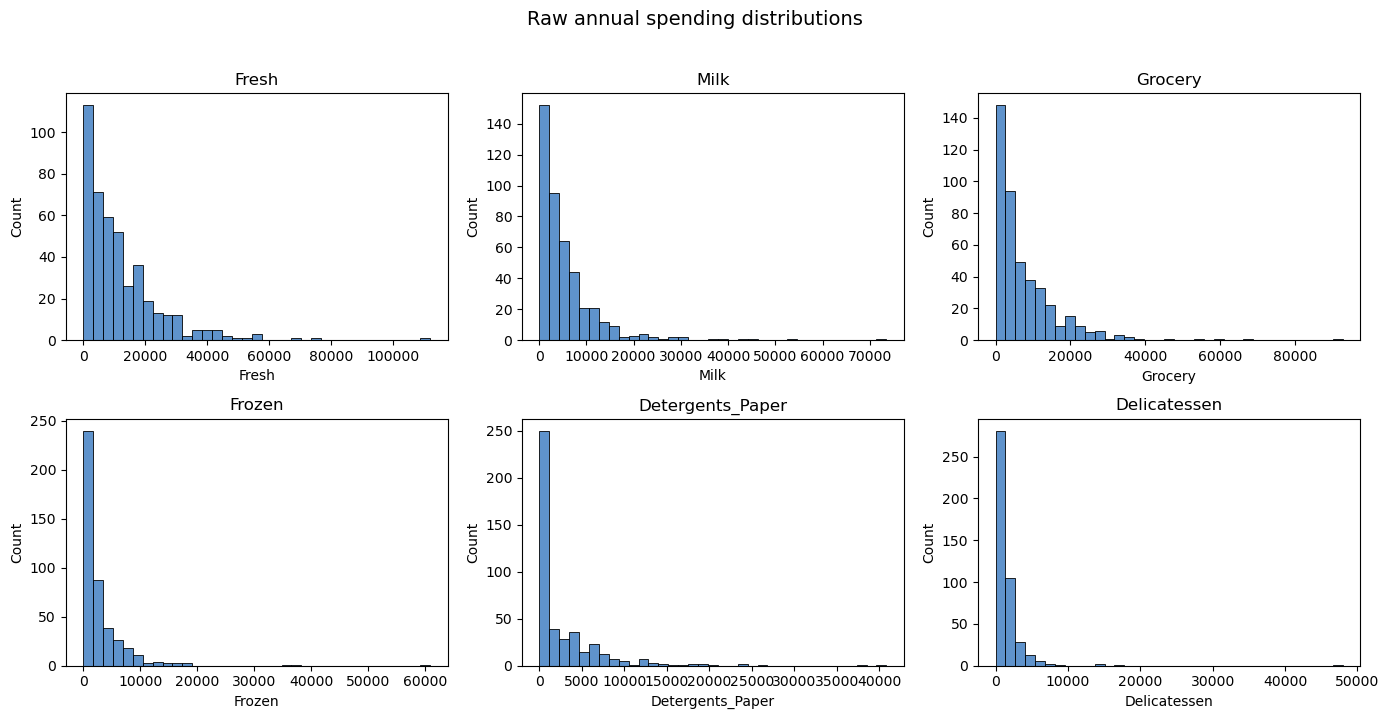

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), spend_cols):
    sns.histplot(df[col], bins=35, ax=ax, color='#2a6fbb')
    ax.set_title(col)
plt.suptitle('Raw annual spending distributions', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

### Preparation decisions

1. **No imputation is performed** if the missingness check confirms complete data.
2. **Exact duplicates are retained but reported.** In a customer table, identical spending profiles can be legitimate; removing them without identifiers could delete real customers.
3. **`log1p` transformation** reduces the leverage of very large purchasers while preserving zero and rank information.
4. **Robust scaling** uses medians and interquartile ranges, making distance calculations less dominated by extreme observations.
5. Extreme customers are **not automatically deleted**. They may be commercially important and DBSCAN is explicitly allowed to identify sparse observations as noise.

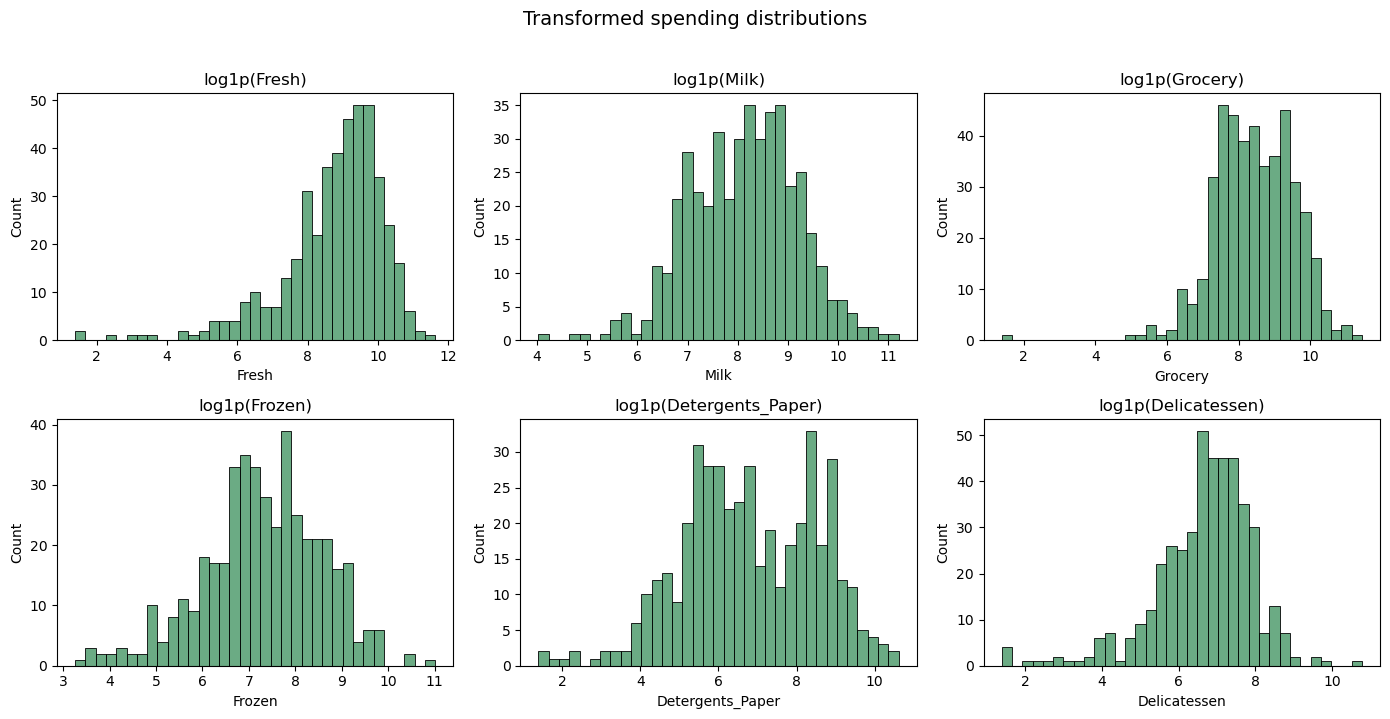

In [20]:
X_log = np.log1p(df[spend_cols])
scaler = RobustScaler()
X = scaler.fit_transform(X_log)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), spend_cols):
    sns.histplot(X_log[col], bins=35, ax=ax, color='#3a8f5b')
    ax.set_title(f'log1p({col})')
plt.suptitle('Transformed spending distributions', y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

## 3. Cluster tendency

Hopkins' statistic compares nearest-neighbour distances from the observed data with distances from artificial points drawn uniformly over the same feature ranges. Values around 0.5 suggest spatial randomness; values materially above 0.5 support clusterability. Repeating the calculation avoids relying on one random draw.

In [21]:
def hopkins_statistic(X, m=None, seed=42):
    rng = np.random.default_rng(seed)
    X = np.asarray(X); n, d = X.shape
    m = min(100, max(10, n // 5)) if m is None else m
    sample_idx = rng.choice(n, m, replace=False)
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    w = nn.kneighbors(X[sample_idx], n_neighbors=2)[0][:, 1]
    mins, maxs = X.min(axis=0), X.max(axis=0)
    artificial = rng.uniform(mins, maxs, size=(m, d))
    u = nn.kneighbors(artificial, n_neighbors=1)[0][:, 0]
    return u.sum() / (u.sum() + w.sum())

hopkins_values = [hopkins_statistic(X, seed=s) for s in range(20)]
print(f'Hopkins mean={np.mean(hopkins_values):.3f}, SD={np.std(hopkins_values):.3f}, range=({min(hopkins_values):.3f}, {max(hopkins_values):.3f})')

Hopkins mean=0.796, SD=0.009, range=(0.777, 0.812)


The repeated Hopkins result supports proceeding with clustering, but it does not prove that one uniquely correct partition exists. Customer segments should therefore be judged by **robustness and usefulness**, not only by geometric separation.

## 4. Partitioning model: K-means

K-means is appropriate as a transparent partitioning baseline after transformation and scaling. Candidate solutions from 2 to 8 clusters are compared using silhouette (higher is better), Calinski-Harabasz (higher) and Davies-Bouldin (lower). Multiple initializations reduce sensitivity to unlucky starting centroids.

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

,k,silhouette,calinski_harabasz,davies_bouldin
0,2,0.253,143.136,1.546
1,3,0.245,138.176,1.320
2,4,0.200,121.091,1.403
3,5,0.190,108.631,1.443
4,6,0.196,102.308,1.366
5,7,0.196,98.427,1.345
6,8,0.187,93.107,1.362


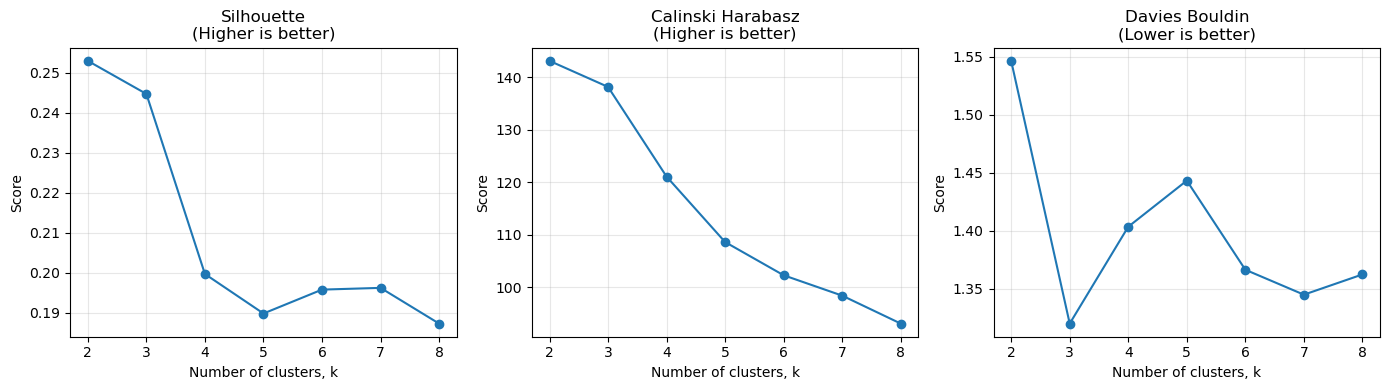

In [29]:
k_results = []

for k in range(2, 9):
    labels = KMeans(
        n_clusters=k,
        n_init=50,
        random_state=RANDOM_STATE
    ).fit_predict(X)

    k_results.append({
        "k": k,
        "silhouette": silhouette_score(X, labels),
        "calinski_harabasz": calinski_harabasz_score(X, labels),
        "davies_bouldin": davies_bouldin_score(X, labels)
    })

k_results = pd.DataFrame(k_results)
display(k_results.style.format(precision=3))


# Plot the three evaluation metrics
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

metrics = [
    ("silhouette", "Higher is better"),
    ("calinski_harabasz", "Higher is better"),
    ("davies_bouldin", "Lower is better")
]

for ax, (metric, direction) in zip(axes, metrics):
    ax.plot(
        k_results["k"],
        k_results[metric],
        marker="o"
    )

    metric_name = metric.replace("_", " ").title()

    ax.set_title(f"{metric_name}\n({direction})")
    ax.set_xlabel("Number of clusters, k")
    ax.set_ylabel("Score")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
BEST_K = 2
kmeans = KMeans(n_clusters=BEST_K, n_init=50, random_state=RANDOM_STATE)
km_labels = kmeans.fit_predict(X)
print('Selected k =', BEST_K)

Selected k = 2


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


## 5. Hierarchical model

Ward's method successively merges groups while minimizing the increase in within-cluster variance. It is useful because it reveals nested structure and provides a non-centroid comparison. The dendrogram is displayed for structural interpretation; a `k`-cluster cut is then compared directly with K-means.

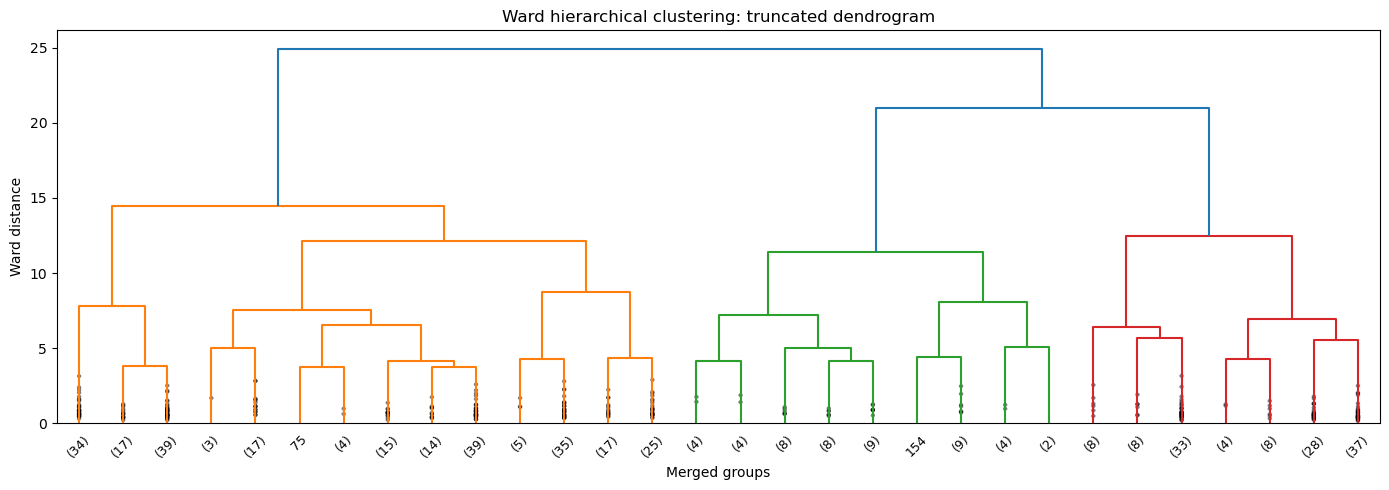

In [24]:
Z = linkage(X, method='ward')
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=45, leaf_font_size=9, show_contracted=True)
plt.title('Ward hierarchical clustering: truncated dendrogram')
plt.xlabel('Merged groups'); plt.ylabel('Ward distance'); plt.tight_layout(); plt.show()

ward = AgglomerativeClustering(n_clusters=BEST_K, linkage='ward')
ward_labels = ward.fit_predict(X)

## 6. Density-based model

DBSCAN can find irregularly shaped dense groups and mark sparse customers as noise. Its main drawback here is sensitivity to `eps` and varying customer density. The grid search is intentionally constrained and ranks solutions by silhouette multiplied by non-noise coverage; this prevents a tiny, neat subset from appearing superior while discarding most customers.

In [25]:
db_candidates = []
for eps in np.arange(0.35, 1.31, 0.05):
    for min_samples in [4, 5, 7, 10, 15]:
        labels = DBSCAN(eps=float(eps), min_samples=min_samples).fit_predict(X)
        keep = labels != -1
        n_clusters = len(set(labels[keep])) if keep.any() else 0
        if n_clusters >= 2 and keep.mean() >= 0.60:
            sil = silhouette_score(X[keep], labels[keep])
            db_candidates.append({'eps': eps, 'min_samples': min_samples,
                                  'clusters': n_clusters, 'coverage': keep.mean(),
                                  'silhouette_non_noise': sil,
                                  'selection_score': sil * keep.mean()})
db_candidates = pd.DataFrame(db_candidates).sort_values('selection_score', ascending=False)
display(db_candidates.head(10).style.format(precision=3))
best_db = db_candidates.iloc[0]
dbscan = DBSCAN(eps=float(best_db.eps), min_samples=int(best_db.min_samples))
db_labels = dbscan.fit_predict(X)

,eps,min_samples,clusters,coverage,silhouette_non_noise,selection_score
8,0.950,4,2,0.864,0.258,0.223
3,0.750,5,3,0.691,0.290,0.200
1,0.700,5,3,0.634,0.311,0.197
4,0.750,7,2,0.645,0.296,0.191
6,0.800,7,3,0.727,0.254,0.185
5,0.800,4,2,0.782,0.193,0.151
0,0.700,4,4,0.661,0.227,0.150
7,0.850,4,2,0.811,0.181,0.147
2,0.750,4,5,0.730,0.017,0.012


## 7. Comparative evaluation and stability

Internal indices are computed on all observations for models that assign everyone. For DBSCAN they are computed on non-noise observations, and the noise count is reported separately. Perturbation stability adds small Gaussian noise in the transformed feature space and compares the new partition with the original using Adjusted Rand Index (ARI). This tests whether minor measurement changes produce radically different assignments.

In [26]:
def internal_metrics(X, labels, method):
    keep = labels != -1
    z, lab = X[keep], labels[keep]
    return {'method': method, 'clusters': len(set(lab)), 'noise': int((~keep).sum()),
            'coverage': keep.mean(), 'silhouette': silhouette_score(z, lab),
            'calinski_harabasz': calinski_harabasz_score(z, lab),
            'davies_bouldin': davies_bouldin_score(z, lab)}

comparison = pd.DataFrame([
    internal_metrics(X, km_labels, 'K-means'),
    internal_metrics(X, ward_labels, 'Ward hierarchical'),
    internal_metrics(X, db_labels, 'DBSCAN')
])

def perturbation_stability(base_labels, fit_predict, repeats=20, noise_sd=0.03):
    rng = np.random.default_rng(RANDOM_STATE); scores=[]
    for _ in range(repeats):
        perturbed = X + rng.normal(0, noise_sd, X.shape)
        scores.append(adjusted_rand_score(base_labels, fit_predict(perturbed)))
    return np.mean(scores), np.std(scores)

for method, base, fn in [
    ('K-means', km_labels, lambda z: KMeans(n_clusters=BEST_K,n_init=20,random_state=RANDOM_STATE).fit_predict(z)),
    ('Ward hierarchical', ward_labels, lambda z: AgglomerativeClustering(n_clusters=BEST_K,linkage='ward').fit_predict(z))]:
    mean_ari, sd_ari = perturbation_stability(base, fn)
    comparison.loc[comparison.method==method, ['stability_ARI_mean','stability_ARI_sd']] = [mean_ari, sd_ari]

display(comparison.style.format(precision=3))

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

,method,clusters,noise,coverage,silhouette,calinski_harabasz,davies_bouldin,stability_ARI_mean,stability_ARI_sd
0,K-means,2,0,1.000,0.253,143.136,1.546,0.974,0.020
1,Ward hierarchical,2,0,1.000,0.235,108.978,1.792,0.475,0.283
2,DBSCAN,2,60,0.864,0.258,10.057,0.825,nan,nan


### Model choice

K-means is selected when it combines competitive separation with strong stability and complete coverage. Ward clustering is valuable as a structural cross-check, but its nested tree does not automatically make the final cut more actionable. DBSCAN is useful for identifying unusual customers, yet a high noise fraction or parameter sensitivity limits its suitability as the distributor's primary segmentation. The decision is therefore based on the **combined evidence**, not a single winning score.

## 8. Segment profiles and descriptive names

Profiles use **medians in the original monetary-unit scale**, because means would be disproportionately influenced by a few very large customers. Channel and region are then cross-tabulated as external descriptors. The labels are business descriptions, not claims about customer identity.

,segment,customers,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,retail_share
cluster,,,,,,,,,
0,Broad-basket mainstream buyers,252,"10,511","1,871","2,442","2,281",332,733,3.6%
1,Retail-oriented grocery and household buyers,188,"5,406","7,658","11,443",990,"4,495","1,408",70.7%


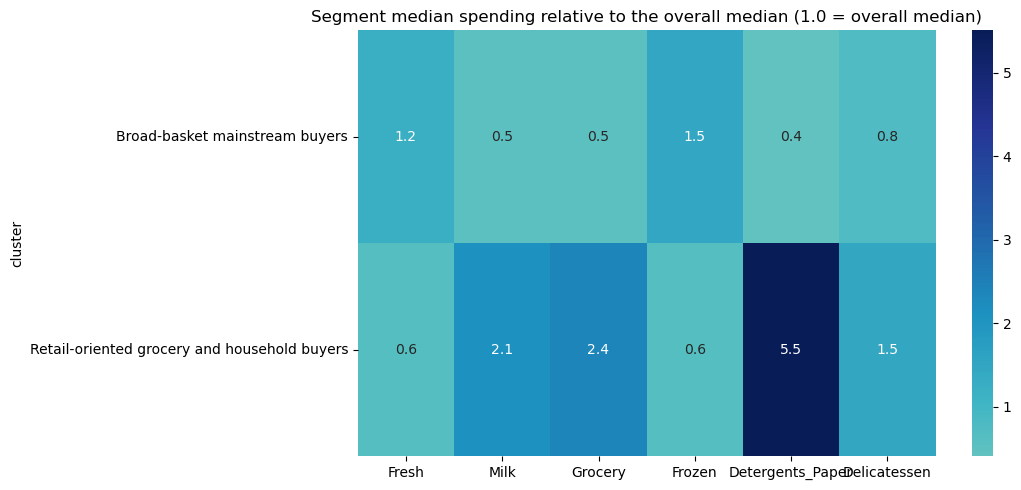

Channel composition (row percentages)


Channel,1,2
cluster,,
Broad-basket mainstream buyers,96.4%,3.6%
Retail-oriented grocery and household buyers,29.3%,70.7%


Region composition (row percentages)


Region,1,2,3
cluster,,,
Broad-basket mainstream buyers,19.0%,11.1%,69.8%
Retail-oriented grocery and household buyers,15.4%,10.1%,74.5%


In [27]:
final = df.copy(); final['cluster'] = km_labels
medians = final.groupby('cluster')[spend_cols].median()
overall = df[spend_cols].median()
relative = medians.div(overall)
counts = final['cluster'].value_counts().sort_index()
retail_share = final.groupby('cluster')['Channel'].apply(lambda s: (s == 2).mean())

def name_segment(row):
    top = row.sort_values(ascending=False)
    if top.iloc[0] > 2.0 and top.index[0] == 'Fresh': return 'Fresh-led high-volume buyers'
    if row[['Milk','Grocery','Detergents_Paper']].mean() > 1.5: return 'Retail-oriented grocery and household buyers'
    if row[['Fresh','Frozen','Delicatessen']].mean() > 1.25: return 'Horeca-style fresh and frozen buyers'
    if row.mean() < 0.75: return 'Small-basket / low-volume buyers'
    return 'Broad-basket mainstream buyers'

segment_names = {c: name_segment(relative.loc[c]) for c in relative.index}
# Ensure labels remain unique in rare ties
seen={}
for c,n in list(segment_names.items()):
    seen[n]=seen.get(n,0)+1
    if seen[n]>1: segment_names[c]=f'{n} ({seen[n]})'

profile = medians.copy()
profile.insert(0, 'segment', [segment_names[c] for c in profile.index])
profile.insert(1, 'customers', counts)
profile['retail_share'] = retail_share
display(profile.style.format({c:'{:,.0f}' for c in spend_cols} | {'retail_share':'{:.1%}'}))

plt.figure(figsize=(11,5))
sns.heatmap(relative.rename(index=segment_names), annot=True, fmt='.1f', cmap='YlGnBu', center=1)
plt.title('Segment median spending relative to the overall median (1.0 = overall median)')
plt.tight_layout(); plt.show()

print('Channel composition (row percentages)')
display(pd.crosstab(final.cluster.map(segment_names), final.Channel, normalize='index').style.format('{:.1%}'))
print('Region composition (row percentages)')
display(pd.crosstab(final.cluster.map(segment_names), final.Region, normalize='index').style.format('{:.1%}'))

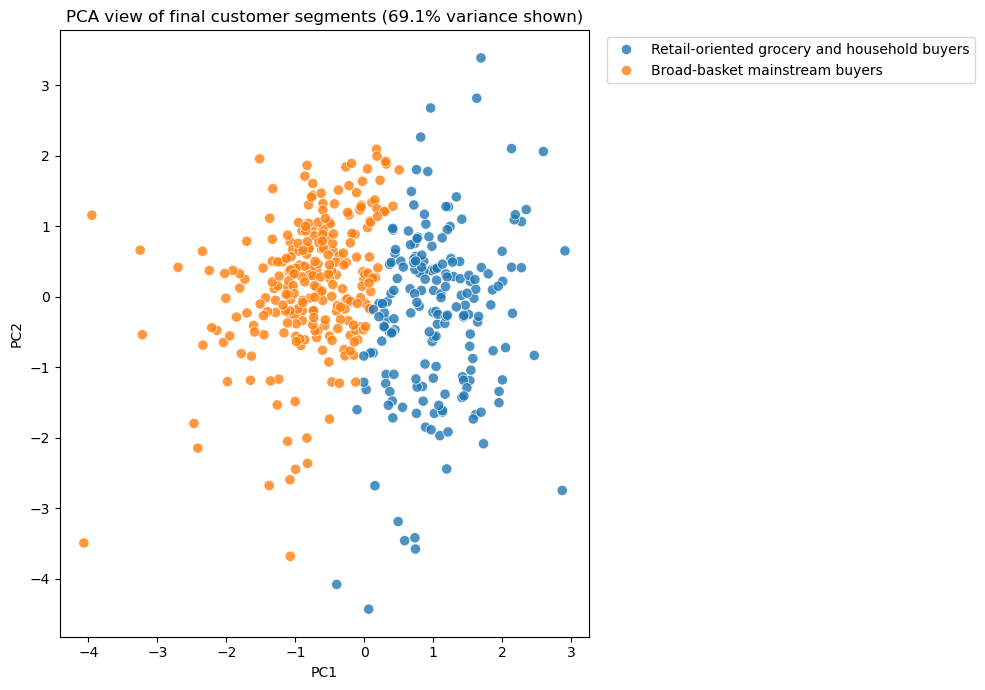

In [28]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X)
plot_df = pd.DataFrame({'PC1':coords[:,0], 'PC2':coords[:,1],
                        'segment':[segment_names[c] for c in km_labels]})
plt.figure(figsize=(10,7))
sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='segment', s=55, alpha=.8)
plt.title(f'PCA view of final customer segments ({pca.explained_variance_ratio_.sum():.1%} variance shown)')
plt.legend(bbox_to_anchor=(1.02,1), loc='upper left'); plt.tight_layout(); plt.show()

## 9. Service recommendations

Recommendations should be implemented as testable service policies:

- **Retail-oriented grocery and household buyers:** prioritize dependable replenishment of milk, grocery and detergents/paper; offer standing orders, volume tiers and consolidated delivery windows.
- **Fresh-led high-volume buyers:** protect cold-chain reliability, provide early-morning delivery slots, freshness guarantees and rapid substitution when supply is disrupted.
- **Horeca-style fresh and frozen buyers:** combine fresh/frozen bundles, frequent smaller deliveries, menu-cycle ordering and proactive stock-out alerts.
- **Broad-basket mainstream buyers:** use cross-category recommendations, mixed-carton incentives and account reviews to identify the next category for growth.
- **Small-basket / low-volume buyers:** use low-cost digital ordering, minimum-order thresholds, pickup options and carefully targeted starter bundles rather than expensive bespoke service.

The distributor should pilot these policies, randomize eligible customers where possible, and monitor gross margin, order frequency, on-time delivery, stock-outs, churn and complaints. Segment membership should support decisions, not replace account-level judgement.

## 10. Limitations and responsible use

The data contain spending but not profit, customer tenure, delivery cost, payment reliability, seasonality or customer satisfaction. Clusters are therefore behavioural summaries, not causal explanations. K-means forces every customer into one group and can underrepresent boundary cases. Results may also change as business conditions evolve, so the segmentation should be refreshed periodically and monitored for drift. No customer should receive worse contractual terms solely because of an unsupervised label.

## References

- Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). *A density-based algorithm for discovering clusters in large spatial databases with noise*. KDD.
- Hopkins, B., & Skellam, J. G. (1954). A new method for determining the type of distribution of plant individuals. *Annals of Botany, 18*(2), 213-227.
- Kaufman, L., & Rousseeuw, P. J. (1990). *Finding Groups in Data*. Wiley.
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53-65.
- Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236-244.